# 2 (HuyTo): Lấy mẫu đều (RUS, Cluster Centroids) & Xóa mẫu dễ/xa biên (CNN, OSS)"

## 2.1 Khởi tạo môi trường chung"

In [2]:
# === CELL KHOI TAO MOI TRUONG CHUNG ===
import os, sys

# Them thu muc goc vao sys.path de import duoc module src.utils
root_dir = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

from src.utils import (
    RANDOM_STATE,
    load_synthetic_data,
    load_real_data,
    get_all_undersamplers,
    get_benchmark_models,
    plot_resampled_comparison,
    plot_decision_boundary,
    plot_pr_curve,
    evaluate_sampler_and_model
)
print('Khoi tao thanh cong! Thu muc goc:', root_dir)

Khoi tao thanh cong! Thu muc goc: f:\PR\PR_Seminar_Undersampling


# Các thuật toán Undersampling

Notebook trình bày riêng từng thuật toán giảm mẫu (undersampling) dành cho dữ liệu mất cân bằng. Mỗi thuật toán được tổ chức theo cùng một cấu trúc:

1. **Mục tiêu và nguyên lý** – thuật toán xử lý lớp đa số như thế nào.
2. **Tham số sử dụng** – giải thích cấu hình trong notebook.
3. **Thực nghiệm** – chạy thuật toán trên cùng tập train.
4. **Kết quả trực quan** – so sánh dữ liệu trước/sau bằng bốn biểu đồ.

## Thiết lập thực nghiệm chung

- Sinh dữ liệu phân loại nhị phân gồm 2.500 mẫu, 2 đặc trưng.
- Tỷ lệ lớp được thiết lập `weights=[0.98, 0.02]`, tức dữ liệu mất cân bằng mạnh.
- Chia train/test theo tỷ lệ 75/25 và dùng `stratify=y` để giữ tỷ lệ lớp.
- Chỉ undersampling tập train; tập test được giữ nguyên.
- Logistic Regression được dùng thống nhất để minh họa Decision Boundary trước và sau undersampling.

> Chạy lần lượt từ trên xuống dưới. Các thuật toán dùng chung dữ liệu và hàm trực quan hóa được khai báo ở phần chuẩn bị.

## 1. Chuẩn bị thư viện, dữ liệu và hàm đánh giá

Phần này chỉ chạy một lần. Các thuật toán ở những phần sau sử dụng chung `X_train`, `y_train` và các hàm vẽ.

### Cấu hình lưu biểu đồ

Tất cả biểu đồ sẽ tự động được lưu dưới định dạng **PNG, độ phân giải 300 DPI** vào:

`F:\\PR\\PR_Seminar_Undersampling\\outputs\\tables`

Notebook tự tạo thư mục nếu chưa tồn tại. Mỗi thuật toán tạo 4 ảnh riêng: `scatter_plot`, `decision_boundary`, `stacked_bar_chart` và `retention_rate`. Tên file có tiền tố là tên thuật toán để tránh ghi đè giữa các phương pháp.

> Đường dẫn này là đường dẫn trên máy Windows. Nếu chạy trên máy khác, hãy sửa biến `OUTPUT_DIR` cho phù hợp.

In [3]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from imblearn.under_sampling import (
    RandomUnderSampler, ClusterCentroids,
    CondensedNearestNeighbour, OneSidedSelection
)

RANDOM_STATE = 42

# Thu muc luu cac bieu do (Windows)
OUTPUT_DIR = r"F:\PR\PR_Seminar_Undersampling\outputs\figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_figure(fig, algorithm_name, chart_name):
    """Luu bieu do thanh PNG voi ten file an toan."""
    safe_algorithm = re.sub(r"[^A-Za-z0-9_-]+", "_", algorithm_name).strip("_")
    safe_chart = re.sub(r"[^A-Za-z0-9_-]+", "_", chart_name).strip("_")
    file_path = os.path.join(OUTPUT_DIR, f"{safe_algorithm}_{safe_chart}.png")
    fig.savefig(file_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Da luu: {file_path}")

X, y = make_classification(
    n_samples=2500, n_features=2, n_informative=2,
    n_redundant=0, n_repeated=0, n_classes=2,
    n_clusters_per_class=2, weights=[0.98, 0.02],
    class_sep=0.85, flip_y=0, random_state=RANDOM_STATE
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
BLUE, RED, GRAY, GOLD = "#2878B5", "#E45756", "#A7A9AC", "#F2B134"

def class_counts(labels):
    c = Counter(labels)
    return c.get(0, 0), c.get(1, 0)

def plot_scatter(ax, Xd, yd, title):
    ax.scatter(Xd[yd==0,0], Xd[yd==0,1], c=BLUE, s=22, alpha=.75,
               edgecolors="none", label="Majority (0)")
    ax.scatter(Xd[yd==1,0], Xd[yd==1,1], c=RED, s=48, marker="^",
               edgecolors="black", linewidths=.35, label="Minority (1)")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2")
    ax.grid(alpha=.2, linestyle="--")

def scatter_chart(name, Xr, yr):
    fig, ax = plt.subplots(1,2,figsize=(13,5))
    plot_scatter(ax[0], X_train, y_train, "Before undersampling")
    plot_scatter(ax[1], Xr, yr, "After undersampling")
    for a in ax: a.legend()
    fig.suptitle(name+" - Scatter Plot 2D", fontsize=14, fontweight="bold")
    plt.tight_layout()
    save_figure(fig, name, "scatter_plot")
    plt.show()

def boundary_chart(name, Xr, yr):
    before = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    after = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    before.fit(X_train,y_train); after.fit(Xr,yr)
    xmin=min(X_train[:,0].min(),Xr[:,0].min())-.7
    xmax=max(X_train[:,0].max(),Xr[:,0].max())+.7
    ymin=min(X_train[:,1].min(),Xr[:,1].min())-.7
    ymax=max(X_train[:,1].max(),Xr[:,1].max())+.7
    xx,yy=np.meshgrid(np.linspace(xmin,xmax,250),np.linspace(ymin,ymax,250))
    grid=np.c_[xx.ravel(),yy.ravel()]
    fig,ax=plt.subplots(1,2,figsize=(13,5))
    for a,model,title in [(ax[0],before,"Before undersampling"),(ax[1],after,"After undersampling")]:
        zz=model.predict(grid).reshape(xx.shape)
        a.contourf(xx,yy,zz,levels=[-.5,.5,1.5],colors=["#B9D8EC","#F5C3C3"],alpha=.55)
        a.contour(xx,yy,zz,levels=[.5],colors=["#30343B"],linewidths=1.8)
        plot_scatter(a,X_test,y_test,title+" (test points)")
    fig.suptitle(name+" - Decision Boundary (Logistic Regression)",fontsize=13,fontweight="bold")
    plt.tight_layout()
    save_figure(fig, name, "decision_boundary")
    plt.show()

def stacked_chart(name, yb, ya):
    bm,bn=class_counts(yb); am,an=class_counts(ya)
    fig,ax=plt.subplots(figsize=(8,5))
    x=np.arange(2); maj=[bm,am]; mino=[bn,an]
    ax.bar(x,maj,color=BLUE,label="Majority (0)")
    ax.bar(x,mino,bottom=maj,color=RED,label="Minority (1)")
    ax.set_xticks(x,["Before","After"]); ax.set_ylabel("Number of samples")
    ax.set_title(name+" - Stacked Bar Chart",fontweight="bold"); ax.legend()
    ax.grid(axis="y",alpha=.2)
    for i,(m,n) in enumerate(zip(maj,mino)):
        ax.text(i,m/2,f"{m:,}",ha="center",va="center",color="white",fontweight="bold")
        ax.text(i,m+n/2,f"{n:,}",ha="center",va="center",color="white",fontweight="bold")
    plt.tight_layout()
    save_figure(fig, name, "stacked_bar_chart")
    plt.show()

def retention_chart(name,yb,ya):
    bm,bn=class_counts(yb); am,an=class_counts(ya)
    vals=[am/bm*100,bn and an/bn*100 or 0,len(ya)/len(yb)*100]
    labels=["Majority","Minority","Total dataset"]
    fig,ax=plt.subplots(figsize=(8,5))
    bars=ax.bar(labels,vals,color=[BLUE,RED,GOLD],width=.58)
    ax.set_ylim(0,110); ax.set_ylabel("Retention rate (%)")
    ax.set_title(name+" - Retention Rate",fontweight="bold"); ax.grid(axis="y",alpha=.2)
    for b,v in zip(bars,vals):
        ax.text(b.get_x()+b.get_width()/2,b.get_height()+2,f"{v:.1f}%",ha="center",fontweight="bold")
    plt.tight_layout()
    save_figure(fig, name, "retention_rate")
    plt.show()

def run_method(name,sampler):
    xr,yr=sampler.fit_resample(X_train,y_train)
    print(name)
    print("Before:",dict(Counter(y_train)))
    print("After: ",dict(Counter(yr)))
    scatter_chart(name,xr,yr)
    boundary_chart(name,xr,yr)
    stacked_chart(name,y_train,yr)
    retention_chart(name,y_train,yr)
    return xr,yr

## 2. Random UnderSampling (RUS)

### 2.1. Mục tiêu và nguyên lý

Random UnderSampling loại bỏ ngẫu nhiên một số mẫu thuộc **lớp đa số** để giảm chênh lệch số lượng giữa hai lớp. Các mẫu lớp thiểu số được giữ lại.

### 2.2. Tham số trong thực nghiệm

- `sampling_strategy=1.0`: sau lấy mẫu, tỷ lệ số mẫu lớp thiểu số/lớp đa số hướng tới 1:1.
- `random_state=RANDOM_STATE`: cố định trạng thái ngẫu nhiên để có thể tái lập kết quả.

### 2.3. Thực hiện

Random UnderSampling (RUS)
Before: {np.int64(0): 1837, np.int64(1): 38}
After:  {np.int64(0): 38, np.int64(1): 38}
Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_RUS_scatter_plot.png


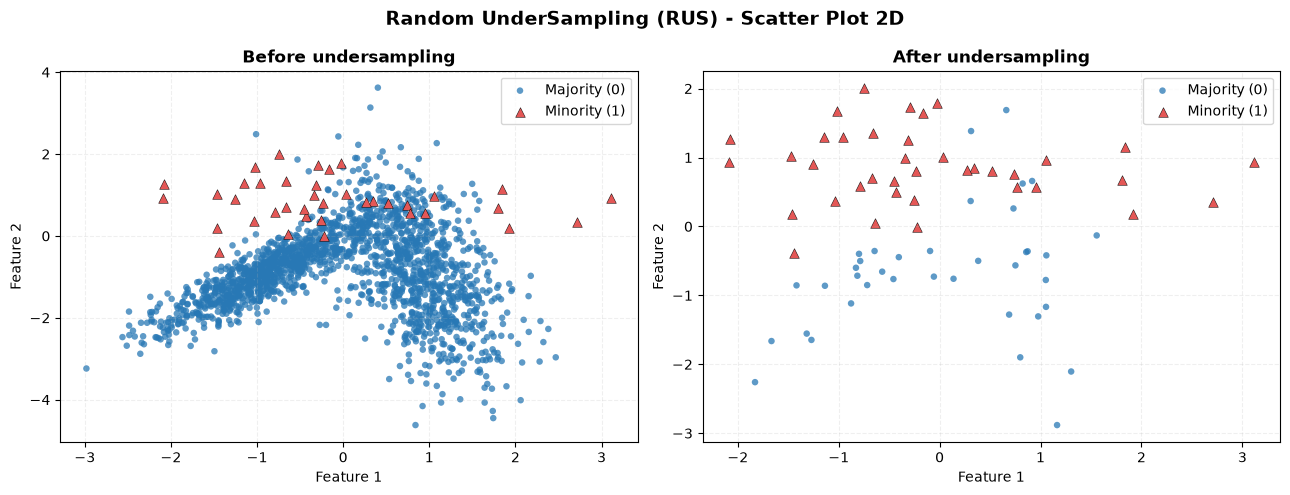

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_RUS_decision_boundary.png


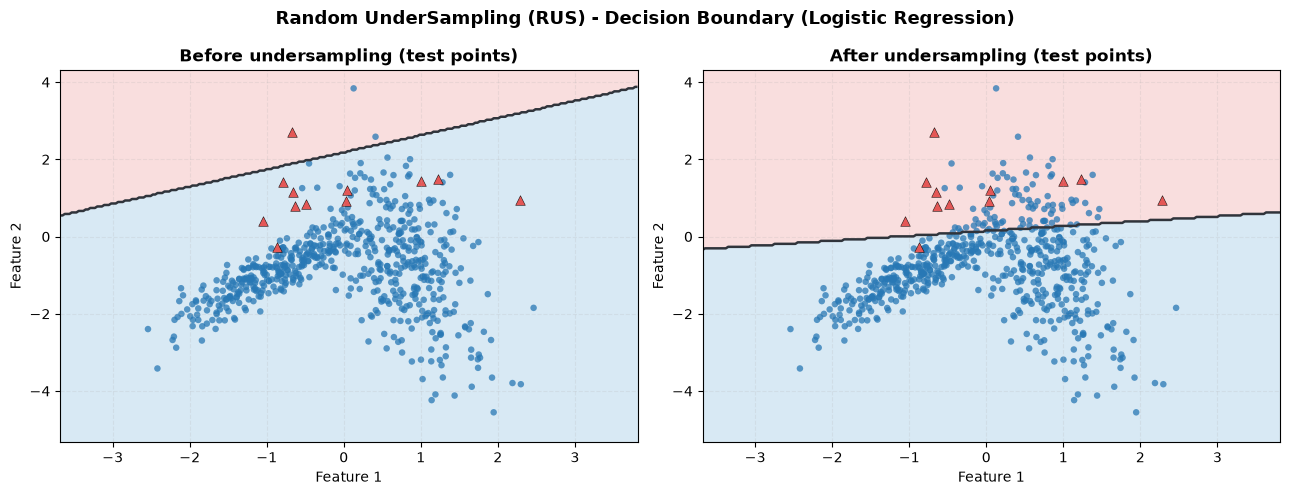

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_RUS_stacked_bar_chart.png


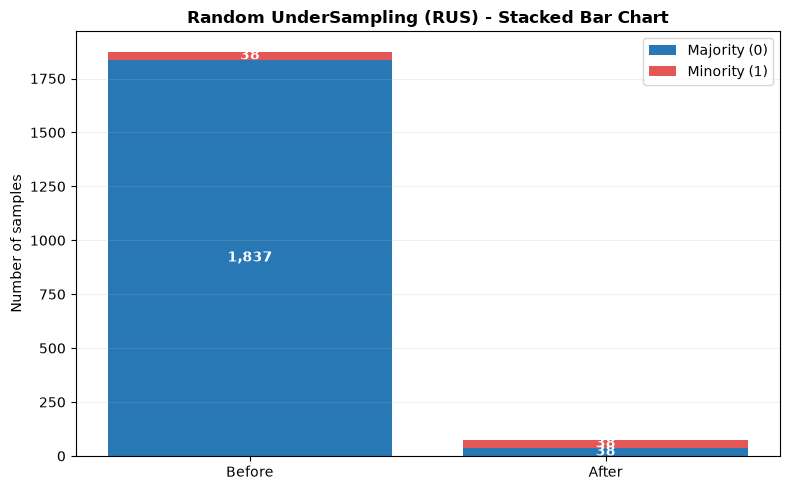

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Random_UnderSampling_RUS_retention_rate.png


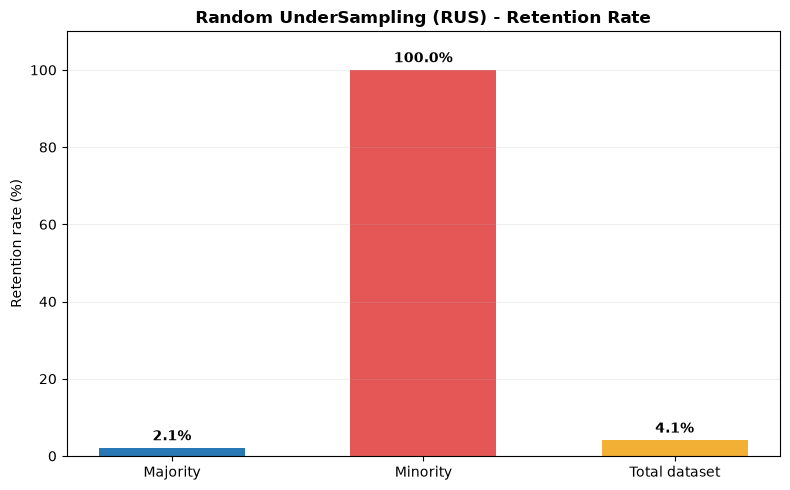

In [4]:
rus = RandomUnderSampler(sampling_strategy=1.0, random_state=RANDOM_STATE)
X_rus, y_rus = run_method("Random UnderSampling (RUS)", rus)

### 2.4. Đọc kết quả

- **Scatter Plot:** quan sát các điểm lớp đa số bị loại bỏ.
- **Decision Boundary:** so sánh ranh giới Logistic Regression học từ dữ liệu gốc và dữ liệu sau RUS.
- **Stacked Bar Chart:** so sánh số lượng hai lớp trước/sau.
- **Retention Rate:** cho biết tỷ lệ mẫu được giữ lại của từng lớp và toàn bộ tập train.

**Điểm cần lưu ý:** do loại mẫu ngẫu nhiên, RUS có thể loại bỏ cả những mẫu lớp đa số có ích cho việc mô tả cấu trúc dữ liệu.

## 3. Cluster Centroids

### 3.1. Mục tiêu và nguyên lý

Cluster Centroids giảm số lượng mẫu lớp đa số bằng cách đại diện các cụm dữ liệu bởi những tâm cụm (centroids). Vì vậy, dữ liệu sau lấy mẫu có thể chứa các điểm đại diện được tính toán, không nhất thiết là những mẫu gốc.

### 3.2. Tham số trong thực nghiệm

- `sampling_strategy=1.0`: đặt mục tiêu cân bằng số lượng hai lớp sau lấy mẫu.
- `random_state=RANDOM_STATE`: cố định trạng thái ngẫu nhiên của quá trình.

### 3.3. Thực hiện

f:\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


Cluster Centroids
Before: {np.int64(0): 1837, np.int64(1): 38}
After:  {np.int64(0): 38, np.int64(1): 38}
Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_scatter_plot.png


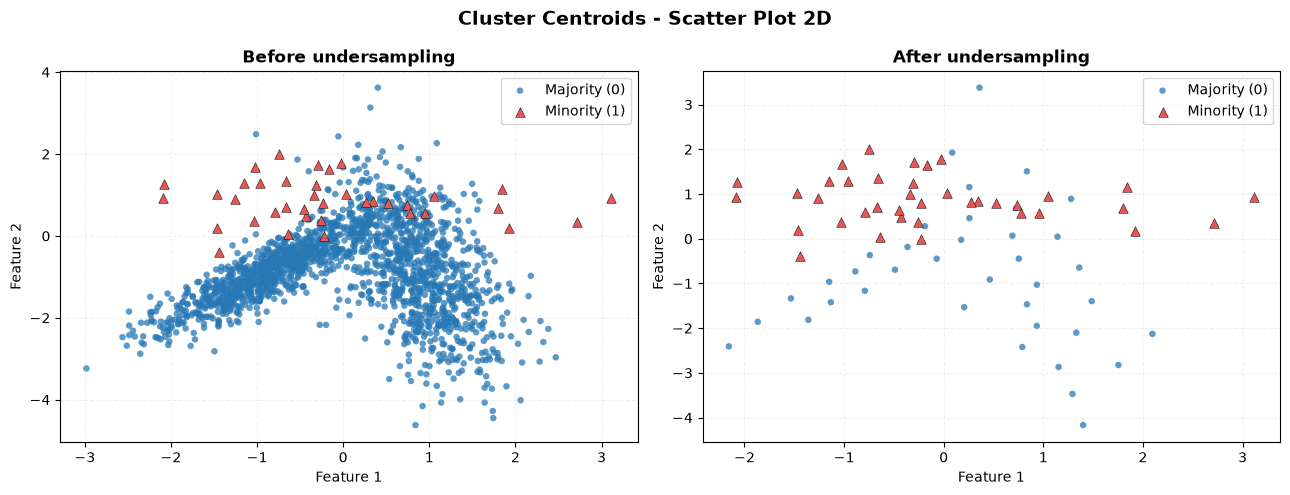

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_decision_boundary.png


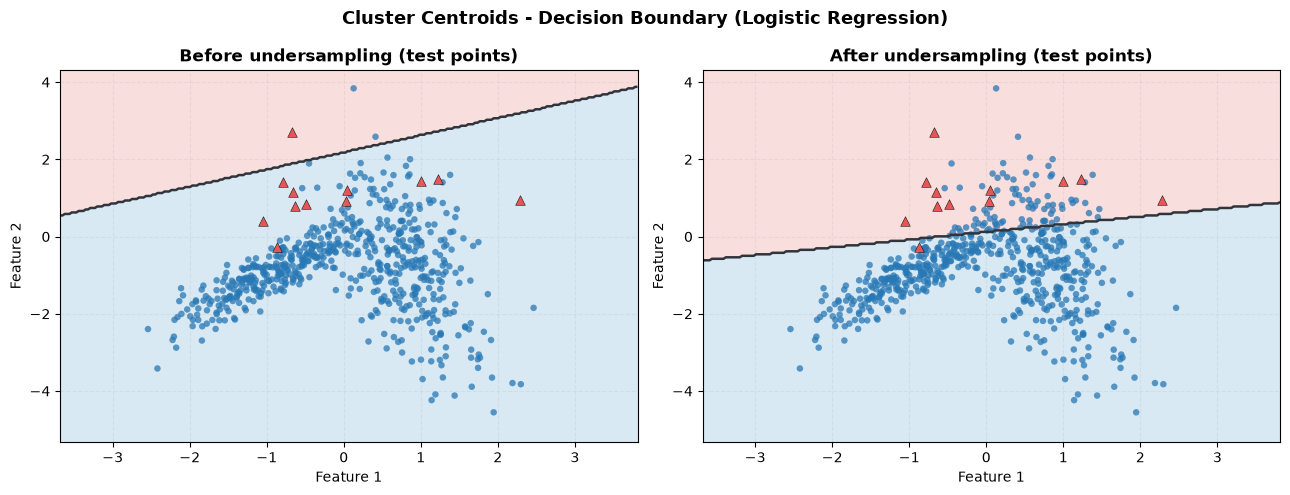

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_stacked_bar_chart.png


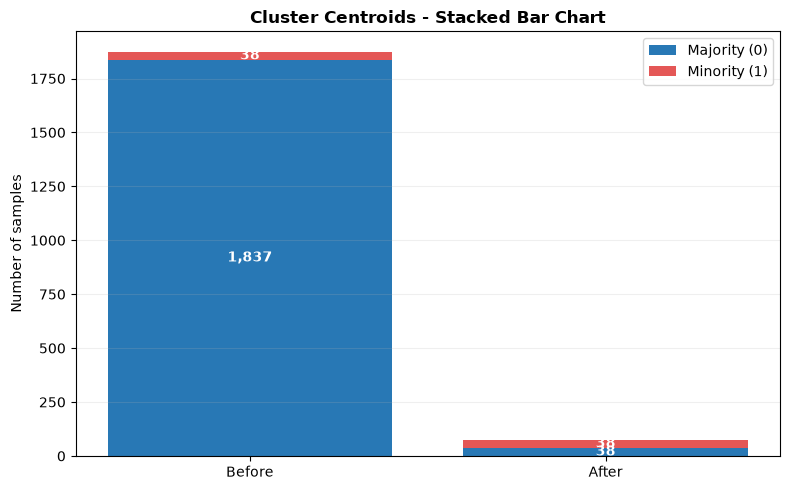

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Cluster_Centroids_retention_rate.png


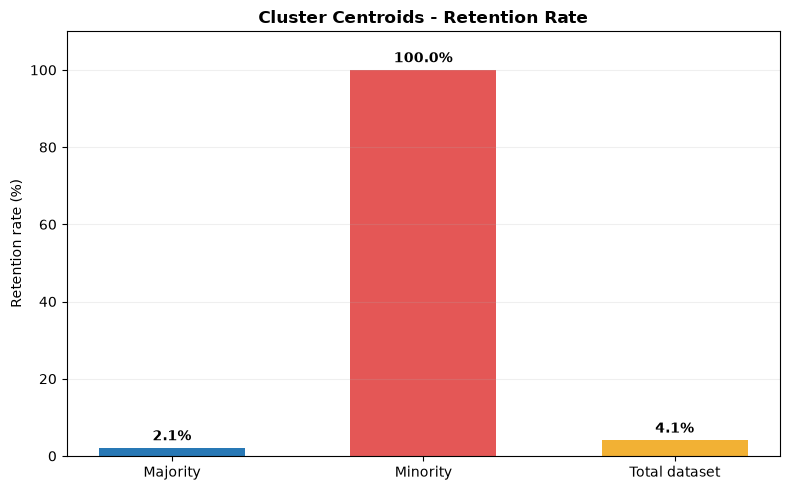

In [5]:
cc = ClusterCentroids(sampling_strategy=1.0, random_state=RANDOM_STATE)
X_cc, y_cc = run_method("Cluster Centroids", cc)

### 3.4. Đọc kết quả

Sử dụng bốn biểu đồ được tạo ra để quan sát mức độ cô đọng của lớp đa số, thay đổi ranh giới phân loại và tỷ lệ mẫu còn lại.

**Điểm cần lưu ý:** các centroid là điểm đại diện tổng hợp; chúng có thể làm mượt cấu trúc dữ liệu và không nhất thiết tương ứng với một quan sát thực tế ban đầu.

## 4. Condensed Nearest Neighbours (CNN)

### 4.1. Mục tiêu và nguyên lý

Condensed Nearest Neighbours xây dựng một tập con đại diện bằng cách lựa chọn các mẫu cần thiết cho quy tắc phân loại láng giềng gần nhất. Những mẫu không cần thiết đối với tập đại diện có thể bị loại bỏ.

### 4.2. Tham số trong thực nghiệm

- `sampling_strategy="auto"`: áp dụng undersampling theo cấu hình mặc định của thư viện đối với lớp cần giảm.
- `random_state=RANDOM_STATE`: cố định trạng thái ngẫu nhiên.
- `n_neighbors=1`: sử dụng 1 láng giềng gần nhất trong bước lựa chọn.

### 4.3. Thực hiện

Condensed Nearest Neighbours (CNN)
Before: {np.int64(0): 1837, np.int64(1): 38}
After:  {np.int64(0): 65, np.int64(1): 38}
Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_CNN_scatter_plot.png


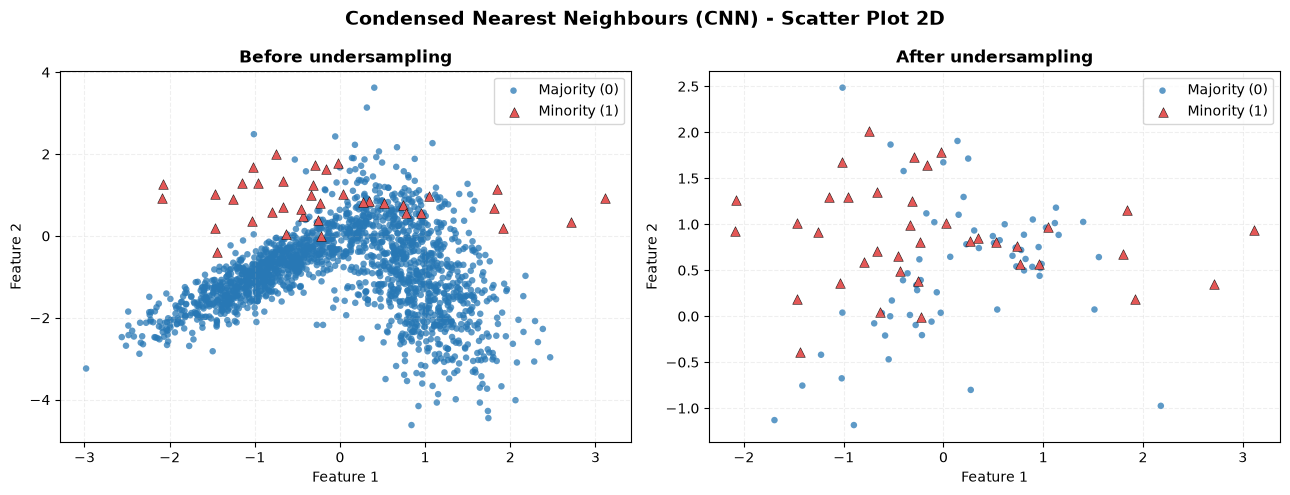

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_CNN_decision_boundary.png


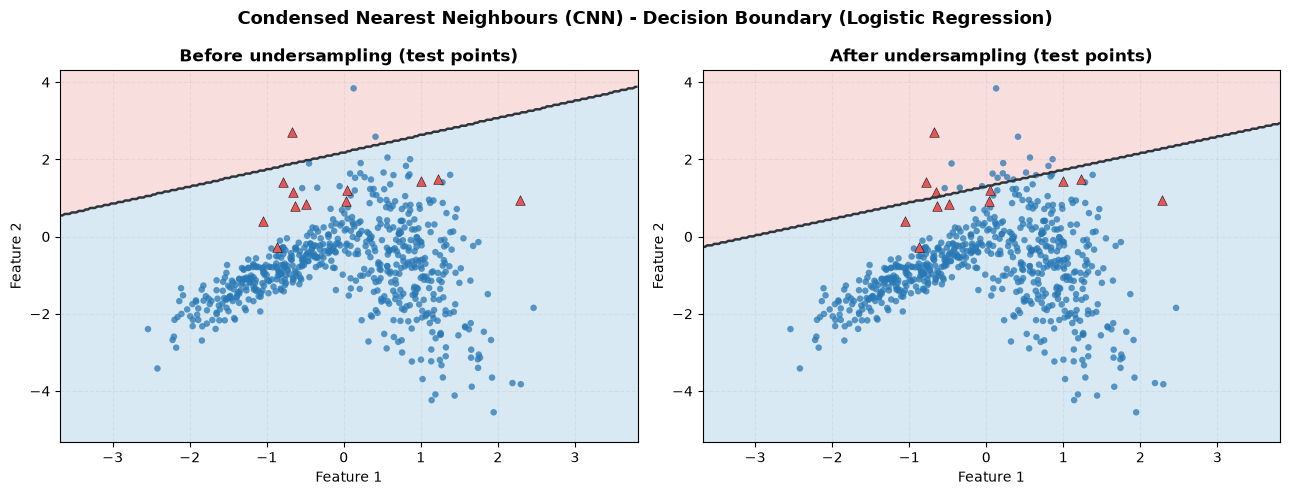

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_CNN_stacked_bar_chart.png


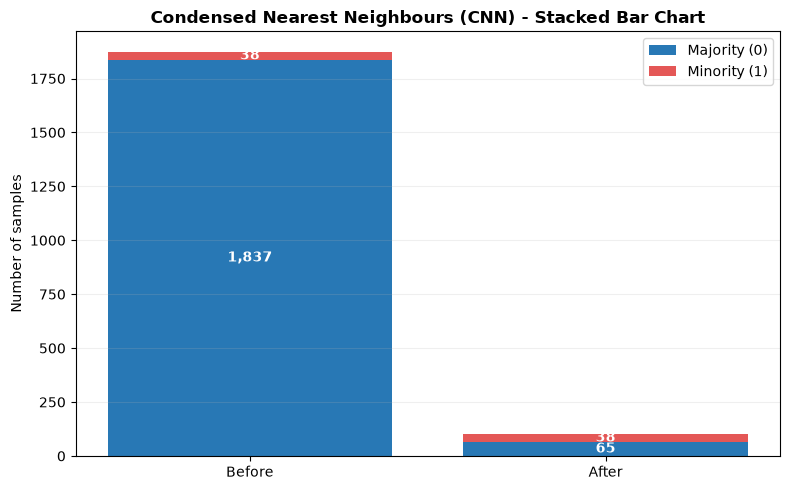

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\Condensed_Nearest_Neighbours_CNN_retention_rate.png


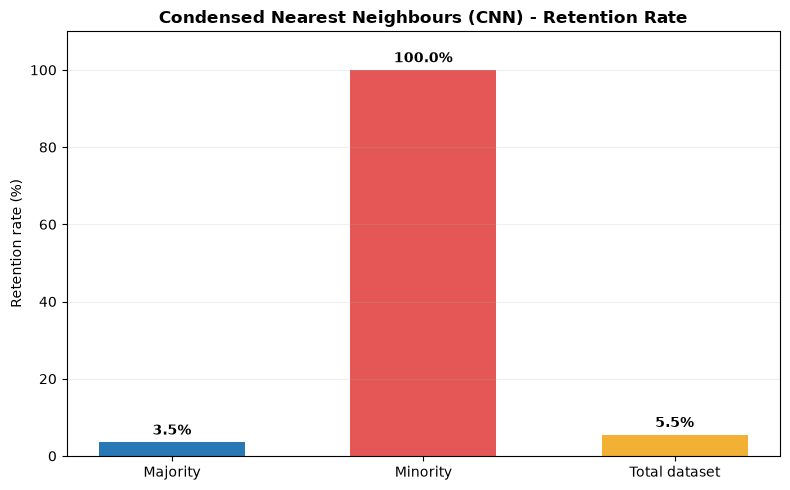

In [6]:
cnn = CondensedNearestNeighbour(sampling_strategy="auto", random_state=RANDOM_STATE, n_neighbors=1)
X_cnn, y_cnn = run_method("Condensed Nearest Neighbours (CNN)", cnn)

### 4.4. Đọc kết quả

Quan sát số mẫu được giữ lại, phân bố không gian và Decision Boundary sau khi tập đại diện được hình thành.

**Điểm cần lưu ý:** CNN có thể giữ lại các điểm gần vùng biên hoặc cần thiết để phân biệt lớp; số lượng mẫu sau xử lý không nhất thiết đạt tỷ lệ cân bằng 1:1.

## 5. One-Sided Selection (OSS)

### 5.1. Mục tiêu và nguyên lý

One-Sided Selection kết hợp ý tưởng lựa chọn mẫu đại diện với việc loại bỏ một số mẫu lớp đa số được xem là dư thừa hoặc gây nhiễu. Phương pháp hướng tới việc giữ lại các mẫu quan trọng, đặc biệt quanh vùng phân cách giữa các lớp.

### 5.2. Tham số trong thực nghiệm

- `sampling_strategy="auto"`: sử dụng chiến lược lấy mẫu mặc định của thư viện.
- `random_state=RANDOM_STATE`: cố định trạng thái ngẫu nhiên.
- `n_seeds_S=10`: số mẫu hạt giống ban đầu được sử dụng để xây dựng tập lựa chọn theo cấu hình này.

### 5.3. Thực hiện

One-Sided Selection (OSS)
Before: {np.int64(0): 1837, np.int64(1): 38}
After:  {np.int64(0): 335, np.int64(1): 38}
Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_OSS_scatter_plot.png


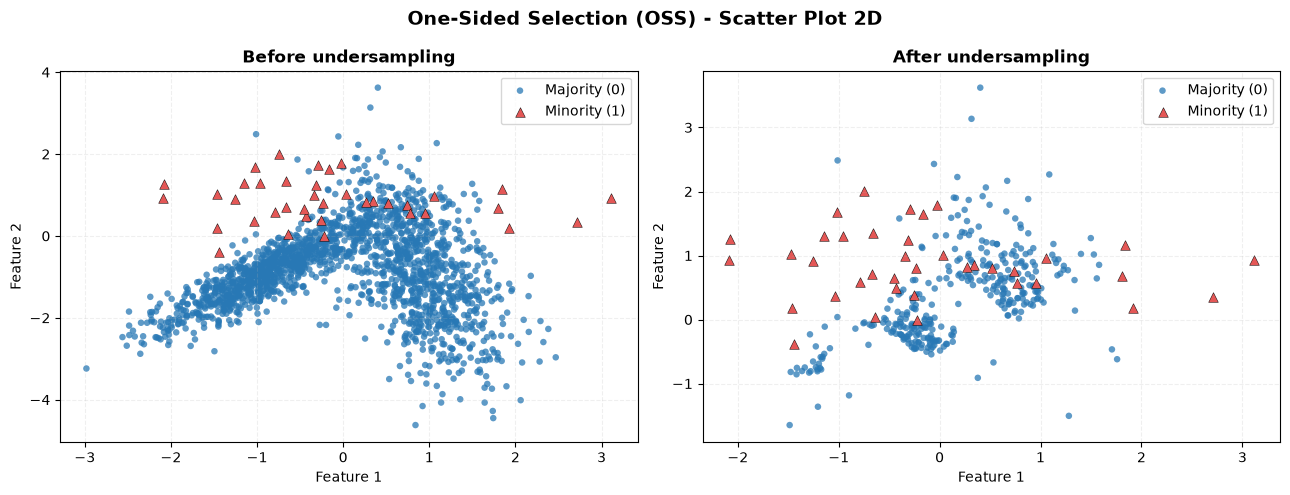

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_OSS_decision_boundary.png


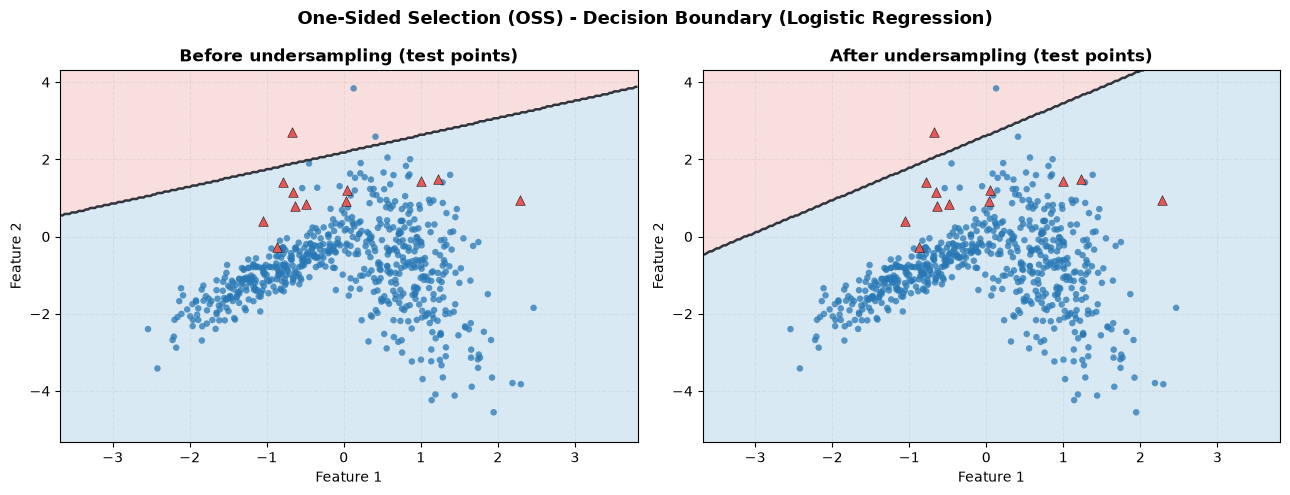

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_OSS_stacked_bar_chart.png


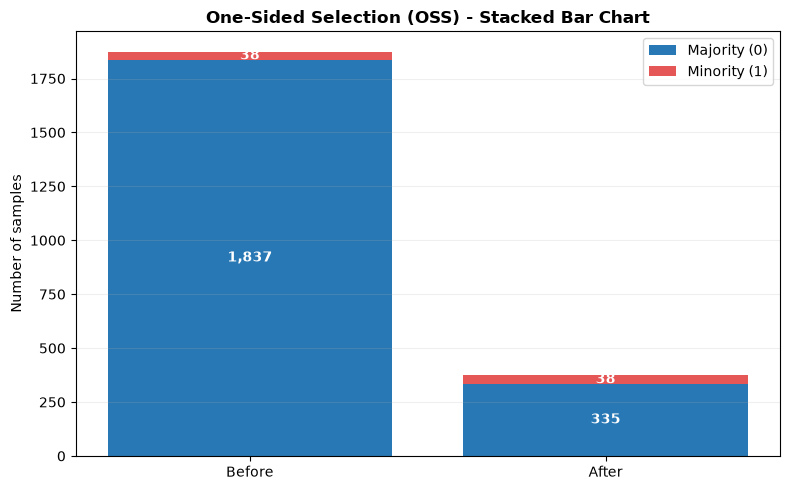

Da luu: F:\PR\PR_Seminar_Undersampling\outputs\figures\One-Sided_Selection_OSS_retention_rate.png


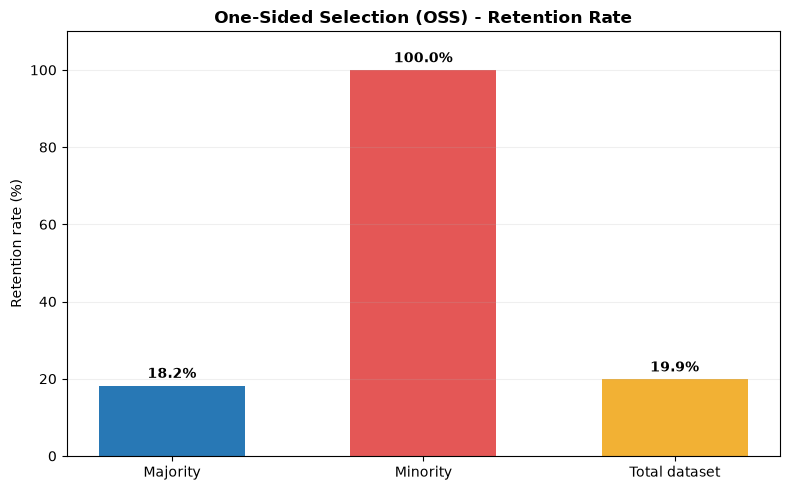

In [7]:
oss = OneSidedSelection(sampling_strategy="auto", random_state=RANDOM_STATE, n_seeds_S=10)
X_oss, y_oss = run_method("One-Sided Selection (OSS)", oss)

### 5.4. Đọc kết quả

Đối chiếu bốn biểu đồ với các phương pháp trước để xem OSS giữ lại những vùng dữ liệu nào, mức độ giảm mẫu và ảnh hưởng tới ranh giới phân loại.

**Điểm cần lưu ý:** OSS không đặt mục tiêu bắt buộc tạo ra hai lớp có số lượng bằng nhau; kết quả phụ thuộc vào cấu trúc dữ liệu và quá trình lựa chọn mẫu.

## 6. Tổng hợp và so sánh các thuật toán

| Thuật toán | Cách giảm mẫu lớp đa số | Đặc điểm cần quan sát |
|---|---|---|
| Random UnderSampling (RUS) | Loại ngẫu nhiên các mẫu lớp đa số | Mức độ ngẫu nhiên và nguy cơ mất mẫu hữu ích |
| Cluster Centroids | Thay thế cụm bằng tâm cụm đại diện | Mức độ cô đọng và thay đổi cấu trúc phân bố |
| Condensed Nearest Neighbours (CNN) | Giữ tập con phục vụ phân loại láng giềng gần nhất | Các mẫu đại diện và mẫu gần biên |
| One-Sided Selection (OSS) | Kết hợp chọn mẫu và loại bỏ mẫu dư thừa/nhiễu | Các mẫu được giữ lại quanh vùng phân cách |

### Tiêu chí đánh giá khi đọc kết quả

1. **Số lượng mẫu:** thuật toán giảm được bao nhiêu mẫu lớp đa số?
2. **Bảo toàn lớp thiểu số:** số mẫu lớp thiểu số có được giữ nguyên không?
3. **Phân bố dữ liệu:** hình dạng và vùng tập trung của dữ liệu thay đổi như thế nào?
4. **Ranh giới phân loại:** Decision Boundary có thay đổi đáng kể không?
5. **Tỷ lệ giữ lại:** so sánh Retention Rate của lớp đa số, lớp thiểu số và toàn bộ tập train.

> Notebook hiện tại trực quan hóa tác động của undersampling. Bốn biểu đồ không thay thế cho đánh giá định lượng bằng các chỉ số như Precision, Recall, F1-score hoặc ROC-AUC.